# Análisis espacial de hurto en Medellín: ¿Dónde se roba en Medellín?

**Curso:** Python 3 · Modelos Macroeconómicos

**Integrantes:** Fernando Jiménez R. · María Vargas E. · Carlos Castro P.

**Facultad de Ciencias Económicas | Universidad de Antioquia**

**Objetivos de la sesión:**
- Descarga de datos de hurto desde MEData entre 2018-2022 y **agregación por barrio.**
- Conversión de conteos a **tasas**: ¿Por qué un barrio con más habitantes no necesariamente es más peligroso?
- Análisis del sesgo del **denominador** cuando el barrio es comercial y no residencial.
- Mapeo espacial con una **escala secuencial de un solo tono**: Tono rojo implica mayor exposición.
- Diferenciación entre el hurto **en la calle** y el hurto **en casa**: El hurto no puede ser generalizado.
- Propuesta de **política**: ¿Qué instrumento corresponde según los patrones hallados en los datos analizados?

---

## I. El caso: ¿El delito persigue a la pobreza o a la oportunidad?

Existe la idea intuitiva de que el delito se concentra en las zonas con mayores carencias urbanas y pobreza de la periferia (como la ladera nororiental). Sin embargo, al analizar los datos oficiales de denuncias de MEData para el periodo 2018–2022, descubrimos que el hurto dibuja un mapa opuesto: se concentra en los barrios de mayores ingresos y mayor tránsito comercial (La Candelaria, Laureles y El Poblado).

El hurto a la propiedad no es una consecuencia directa de la carencia urbana, sino un **delito de oportunidad**: ocurre donde hay flujo de personas, actividad económica y bienes de alto valor.

Es por esto que es importante destacar el hecho de que la carencia y el hurto son dos problemas distintos, que requieren de políticas diferenciadas.

### Lectura: Medición del delito en cinco ideas

1. **Tasas en lugar de conteos brutos:** No basta con contar cuántos robos ocurren en un barrio. Los barrios más poblados siempre tendrán más casos. Para comparar objetivamente, calculamos la **tasa por cada 100.000 habitantes**.
2. **El engaño del denominador (Población flotante):** Sectores como El Poblado (zona comercial con 408 residentes) o Tenche (zona industrial con 21 residentes) muestran tasas gigantescas si solo se divide por sus habitantes nocturnos. Estas áreas reciben miles de visitantes diarios; por ende, el delito afecta a la población flotante y no únicamente a los residentes.
3. **Diferenciación de delitos (Calle vs. Vivienda):** El hurto a personas en vía pública es un delito de movilidad y oportunidad que afecta al peatón; el hurto a residencia afecta al habitante en su hogar. Confundirlos conduce a esquemas de patrullaje ineficaces.
4. **Criterio visual en la escala:** Un mapa cambia drásticamente según cómo se agrupen sus rangos de color. Para evitar distorsiones visuales, se adopta una escala secuencial fija de un solo tono (rojo).
5. **Del mapa a la política pública:** El mapa responde a la pregunta de **dónde** ocurre el delito. La política operativa exige entender el **cómo** (modalidad) y el **cuándo** (pico laboral de 17:00 a 20:00 horas).

## II. Preguntas guía que este notebook responde

1. ¿El hurto en Medellín se concentra en la periferia vulnerable o sigue la concentración de riqueza y flujo comercial?
2. ¿El mapa del delito cambia si analizamos el hurto en la calle frente al hurto a viviendas?
3. ¿Qué implicaciones de política pública surgen al diferenciar el delito de oportunidad del delito residencial?

## III. Preguntas de discusión introductorias

1. Si la pobreza se concentra en la periferia pero el hurto en el centro y sur rico, ¿debería el presupuesto de seguridad distribuirse por niveles de carencia o por concentración delictiva?
2. ¿Cómo afecta a las estadísticas calcular tasas por residente en sectores comerciales como El Poblado o Tenche, por donde transitan miles de personas pero duermen muy pocas?

---

## IV. Los datos: La fuente de información

Analizamos seis conjuntos de datos de denuncias de la Alcaldía de Medellín para el periodo **2018–2022** disponibles en MEData. Excluimos tanto al año 2023 por estar incompleto (contiene registros hasta noviembre) como al hurto a establecimientos comerciales por haber descontinuado su medición en 2017.

Estos conjuntos de datos (siete en total) corresponden a un **código de barrio** y una fecha del hecho, desde 2003 a noviembre de 2023, seis de los cuales fueron tomados en cuenta para el análisis durante el período en cuestión:

| Capa | Qué trae |
|---|---|
| **Hurto a persona** | 326.489 casos; lugar, modalidad, arma, sexo, edad |
| **Hurto a residencia** | 42.673 casos |
| **Hurto de moto / carro** | 86.410 y 39.571 casos |
| **Piratería terrestre, entidad financiera** | 2.202 y 289 casos |
| ~~Hurto a establecimiento comercial~~ | 16.950 casos, **solo hasta 2017** |

In [2]:
import sys

from pathlib import Path

import warnings
warnings.filterwarnings('ignore')

RAIZ = Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))

import geopandas as gpd
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

from esda.moran import Moran, Moran_Local

from libpysal.weights import Queen

# Importación de Modulos Locales del Proyecto
from rampa import rampa, ROJA, SIN_DATOS
import mapa_hurto
import export   

# Rutas Principales
RAIZ = Path.cwd().parents[0]
DATOS = RAIZ / "datalake/data/raw/medellin"
SEGURIDAD = DATOS / "seguridad"
SALIDA = RAIZ / "datalake/data/processed/hurto"

# Directorios
DATOS.mkdir(parents=True, exist_ok=True)
SEGURIDAD.mkdir(parents=True, exist_ok=True)
SALIDA.mkdir(parents=True, exist_ok=True)

def descargar(url, archivo, carpeta=DATOS):
    """Baja `url` una vez y reutiliza la copia local."""
    carpeta.mkdir(parents=True, exist_ok=True)
    ruta = carpeta / archivo
    if not ruta.exists():
        # Sin User-Agent el servidor de la Alcaldía responde 403
        respuesta = requests.get(url, headers={"User-Agent": "Mozilla/5.0"},
                                 timeout=600)
        respuesta.raise_for_status()
        ruta.write_bytes(respuesta.content)
    return ruta


MEDATA = "https://medata.app.medellin.gov.co/sites/default/files/distribution"
MAPAS = "https://www.medellin.gov.co/servidormapas/rest/services/ServiciosCiudad"

URLS = {
    "persona": f"{MEDATA}/1-027-23-000011/hurto_a_persona.csv",
    "residencia": f"{MEDATA}/1-027-23-000012/hurto_a_residencia.csv",
    "moto": f"{MEDATA}/1-027-23-000014/hurto_de_moto.csv",
    "carro": f"{MEDATA}/1-027-23-000013/hurto_de_carro.csv",
    "pirateria": f"{MEDATA}/1-027-23-000016/hurto_por_pirateria_terrestre.csv",
    "entidad_financiera": f"{MEDATA}/1-027-23-000009/hurto_a_entidad_financiera.csv",
}
URL_BARRIOS = (f"{MAPAS}/MAP6_Indicadores/MapServer/6/query?where=1%3D1"
               "&outFields=codigo,nombre,limitecomunacorregimientoid,"
               "subtipo_barriovereda&outSR=4326&f=geojson")
URL_BATERIA = (f"{MEDATA}/1-002-26-000595/"
               "base_datos_bateria_indicadores_capacidad_soporte_barrio.csv")

ARCHIVOS = {clave: descargar(url, f"hurto_{clave}.csv", SEGURIDAD)
            for clave, url in URLS.items()}
print(f"{len(ARCHIVOS)} conjuntos de hurto en {SEGURIDAD}")

6 conjuntos de hurto en c:\Users\USER\Documents\Marie's\Uni\UdeA\Python\Hurto_Medellin_Proyecto\datalake\data\raw\medellin\seguridad


---

### 4.1. Agregación por barrio

Para comparar barrios de distinto tamaño, calculamos la **tasa anual por 100.000 habitantes**.

### Acotación: El sesgo del denominador

Al analizar las tasas, identificamos el **sesgo del denominador**: barrios industriales o comerciales como Tenche (21 habitantes) o sectores de El Poblado muestran tasas de cientos de miles de hurtos por habitante. Esto es un artefacto estadístico, pues el delito no afecta a los pocos residentes que duermen allí, sino a la masa de población flotante (visitantes) que transita durante el día.

Para corregir este sesgo sin perder comparabilidad, filtramos únicamente los barrios con **2.000 o más residentes**.

> **Momento de duda:** ¿Qué barrios consideran que registran los mayores hurtos por habitante?

In [3]:
ANIO_INI, ANIO_FIN = 2018, 2022
ANIOS = ANIO_FIN - ANIO_INI + 1
POBLACION_MINIMA = 2_000    # piso del denominador
ESCALA = 100_000            # tasa por 100.000 habitantes


def cargar_hurtos():
    """Una columna por tipo de hurto, indexada por código de barrio."""
    partes = []
    for clave, ruta in ARCHIVOS.items():
        df = pd.read_csv(ruta, dtype=str, low_memory=False,
                         usecols=["fecha_hecho", "codigo_barrio", "cantidad"])
        df["anio"] = pd.to_datetime(df["fecha_hecho"], errors="coerce").dt.year
        df = df[df["anio"].between(ANIO_INI, ANIO_FIN)]
        # El codigo viene con '#' adelante: '#1103' -> '1103'
        df["codigo"] = df["codigo_barrio"].str.lstrip("#").str.strip()
        df["cantidad"] = pd.to_numeric(df["cantidad"], errors="coerce").fillna(1)
        partes.append(df.groupby("codigo")["cantidad"].sum().rename(clave))
    return pd.concat(partes, axis=1).fillna(0)


def tasa(conteo, poblacion):
    """Hurtos por 100.000 habitantes y por año."""
    return ESCALA * conteo / poblacion / ANIOS


TIPOS = list(URLS)
hurtos = cargar_hurtos()
print(f"Hurtos 2018-2022 en {len(hurtos)} códigos de barrio")
print(hurtos.sum().sort_values(ascending=False).to_string())

Hurtos 2018-2022 en 333 códigos de barrio
persona               184582.0
moto                   24625.0
residencia             19893.0
carro                   4805.0
entidad_financiera        38.0
pirateria                 12.0


In [4]:
barrios = gpd.read_file(descargar(URL_BARRIOS, "barrios.geojson"))
barrios = barrios[(barrios["subtipo_barriovereda"] == 1)
                  & ~barrios["codigo"].str.startswith("Inst_")]

bateria = pd.read_csv(descargar(URL_BATERIA, "bateria_barrios.csv"), dtype=str)
bateria = bateria[(bateria["Desag"] == "Barrio") & (bateria["Anio"] == "2021")]
bateria["Valor"] = pd.to_numeric(bateria["Valor"].str.replace(",", "."),
                                 errors="coerce")
indicadores = bateria.pivot_table(index="Cod_Barrio", columns="Nom_Ind",
                                  values="Valor")
COMUNAS = bateria.groupby("Cod_Com")["Nom_Com"].first()

barrios = barrios.set_index("codigo").join(hurtos, how="inner")
barrios[TIPOS] = barrios[TIPOS].fillna(0)
barrios["poblacion"] = indicadores["Población total"]
barrios["comuna"] = barrios["limitecomunacorregimientoid"].map(COMUNAS)
barrios["estrato_1_2"] = (indicadores["Población estrato 1"]
                          + indicadores["Población estrato 2"])
barrios["pct_estrato_1_2"] = 100 * barrios["estrato_1_2"] / barrios["poblacion"]

# Barrios de 21 habitantes (Tenche, zona industrial) distorsionan la tasa
barrios = barrios[barrios["poblacion"] >= POBLACION_MINIMA]

barrios["total"] = barrios[TIPOS].sum(axis=1)
barrios["tasa"] = tasa(barrios["total"], barrios["poblacion"])
# El hurto a persona ocurre casi todo en via publica: es el riesgo de transitar.
# El hurto a residencia es el riesgo de quien vive ahi. No son lo mismo.
barrios["tasa_calle"] = tasa(barrios["persona"], barrios["poblacion"])
barrios["tasa_residencia"] = tasa(barrios["residencia"], barrios["poblacion"])

print(f"Ventana: {ANIO_INI}-{ANIO_FIN} ({ANIOS} años)")
print(f"Barrios: {len(barrios)}  ·  Población: {barrios['poblacion'].sum():,.0f}")
print(f"Hurtos: {barrios['total'].sum():,.0f}")
print(f"Tasa de la ciudad: "
      f"{tasa(barrios['total'].sum(), barrios['poblacion'].sum()):,.0f} "
      f"por 100.000 hab/año")

Ventana: 2018-2022 (5 años)
Barrios: 230  ·  Población: 2,221,612
Hurtos: 185,526
Tasa de la ciudad: 1,670 por 100.000 hab/año


### Los 10 barrios con más hurto por habitante

In [5]:
cols = ["nombre", "comuna", "poblacion", "pct_estrato_1_2", "total",
        "tasa", "tasa_calle", "tasa_residencia"]
print("=== Los 10 barrios con más hurto por habitante ===")
print(barrios.nlargest(10, "tasa")[cols].round(0).to_string(index=False))

=== Los 10 barrios con más hurto por habitante ===
        nombre           comuna  poblacion  pct_estrato_1_2   total     tasa  tasa_calle  tasa_residencia
 La Candelaria    La Candelaria     3535.0              0.0 19666.0 111264.0    109086.0            736.0
  Barrio Colón    La Candelaria     3164.0              7.0  4021.0  25417.0     24140.0            442.0
 La Aguacatala       El Poblado     2290.0              0.0  1768.0  15441.0     14507.0            410.0
Jesús Nazareno    La Candelaria     2235.0              1.0  1626.0  14550.0     12671.0            465.0
   Bolivariana Laureles Estadio     3820.0              0.0  2648.0  13864.0     12482.0            723.0
   Villa Nueva    La Candelaria     4443.0              0.0  3046.0  13711.0     12460.0            351.0
      Guayabal         Guayabal     2306.0              0.0  1192.0  10338.0      8838.0            208.0
       Estadio Laureles Estadio     4631.0              0.0  2393.0  10335.0      8927.0            8

Los diez primeros son **La Candelaria** (el centro), **Laureles** y **El Poblado**.
Ni uno solo está en la periferia pobre. Compárese con la sesión 6, donde cinco de
los diez peores entornos urbanos estaban en Manrique, en la ladera nororiental.

### Hallazgos socioeconómicos clave: El hurto sigue a la plata, no a la carencia

| Grupo de barrios | Barrios | Población | Hurtos | Tasa |
|---|---|---|---|---|
| Ricos (< 20% estrato 1-2) | 119 | 958.000 | 147.355 | **3.076** |
| Medios | 34 | 391.000 | 19.208 | 981 |
| Pobres (> 80% estrato 1-2) | 77 | 872.000 | 18.963 | **435** |

**Relación:** Los barrios con mayores ingresos registran una tasa **7 veces superior** a la de los barrios vulnerables, reflejando una correlación de Spearman de **ρ = -0,86**.

In [6]:
print("Tasa por grupo socioeconómico")
for etiqueta, sub in [
    ("Ricos  (<20% estrato 1-2)", barrios[barrios["pct_estrato_1_2"] < 20]),
    ("Medios (20-80%)", barrios[(barrios["pct_estrato_1_2"] >= 20)
                                & (barrios["pct_estrato_1_2"] < 80)]),
    ("Pobres (>80% estrato 1-2)", barrios[barrios["pct_estrato_1_2"] >= 80]),
]:
    print(f"  {etiqueta:<26} n={len(sub):>3}  "
          f"población={sub['poblacion'].sum():>9,.0f}  "
          f"hurtos={sub['total'].sum():>7,.0f}  "
          f"tasa={tasa(sub['total'].sum(), sub['poblacion'].sum()):>6,.0f}")

print()
for col in ["tasa", "tasa_calle", "tasa_residencia"]:
    rho = barrios[col].corr(barrios["pct_estrato_1_2"], method="spearman")
    print(f"  {col:<18} vs % estrato 1-2:  rho = {rho:+.2f}")

Tasa por grupo socioeconómico
  Ricos  (<20% estrato 1-2)  n=119  población=  957,988  hurtos=147,355  tasa= 3,076
  Medios (20-80%)            n= 34  población=  391,454  hurtos= 19,208  tasa=   981
  Pobres (>80% estrato 1-2)  n= 77  población=  872,170  hurtos= 18,963  tasa=   435

  tasa               vs % estrato 1-2:  rho = -0.86
  tasa_calle         vs % estrato 1-2:  rho = -0.85
  tasa_residencia    vs % estrato 1-2:  rho = -0.85


---

### 4.2. Visualización Cartográfica: Una escala de un solo tono

Utilizamos una escala de color secuencial en un solo tono (rojo), donde una mayor intensidad de color representa una mayor tasa delictiva. El color gris se reserva exclusivamente para los barrios "sin datos", evitando confundir la falta de información con un nivel bajo de delito.

Además, la elección del color **rojo** se debe a su utilidad semántica, es decir, podría interpretarse en un mapa de delito como signo de peligro.

| Clase | Hurtos por 100.000 hab/año |
|---|---|
| Clase 1 | menos de 500 |
| Clase 2 | 500 – 1.500 |
| Clase 3 | 1.500 – 3.000 |
| Clase 4 | 3.000 – 8.000 |
| Clase 5 | más de 8.000 |

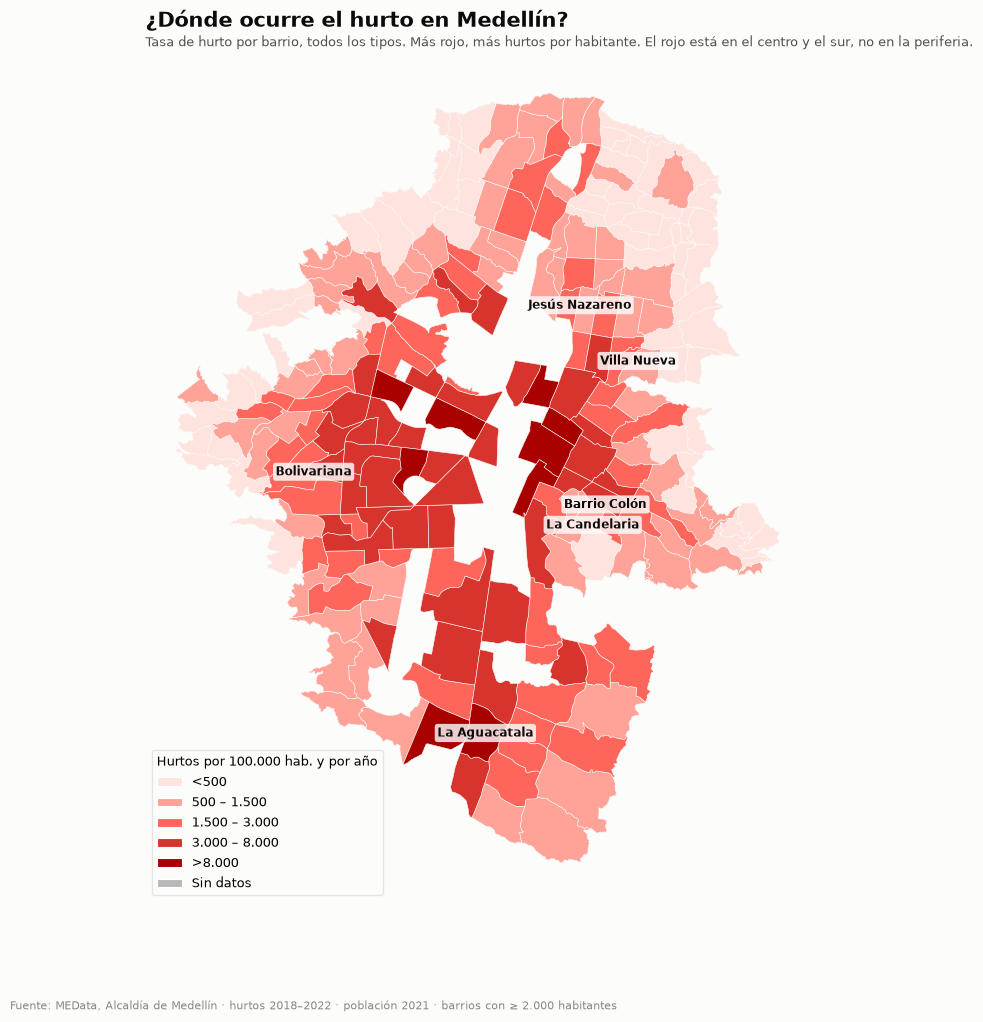

In [7]:
# Coordenadas de ajuste de etiquetas para el mapa general
ANOTAR_BARRIOS = [ ("1019", (900, -1500)), ("1013", (1500, -300)), ("1422", (0, 0)), ("1003", (700, 1600)), ("1107", (-1900, 0)), ("1018", (1500, 1300)) ]
# Renderizado de la Vista 0 (Hurto Total)
mapa_hurto.dibujar(barrios, mapa_hurto.VISTAS[0], anotar=ANOTAR_BARRIOS)

### Diferencias: El mismo mapa, ¿pero y el hurto en casa?

El hurto **a persona** ocurre en vía pública (45% de los casos): lo sufre quien
transita. El hurto **a residencia** lo sufre quien vive ahí.
Si el primero dice dónde hay que cuidar la calle, el segundo dice dónde hay que cuidar la casa.

Cuando se separan, el mapa cambia de forma.

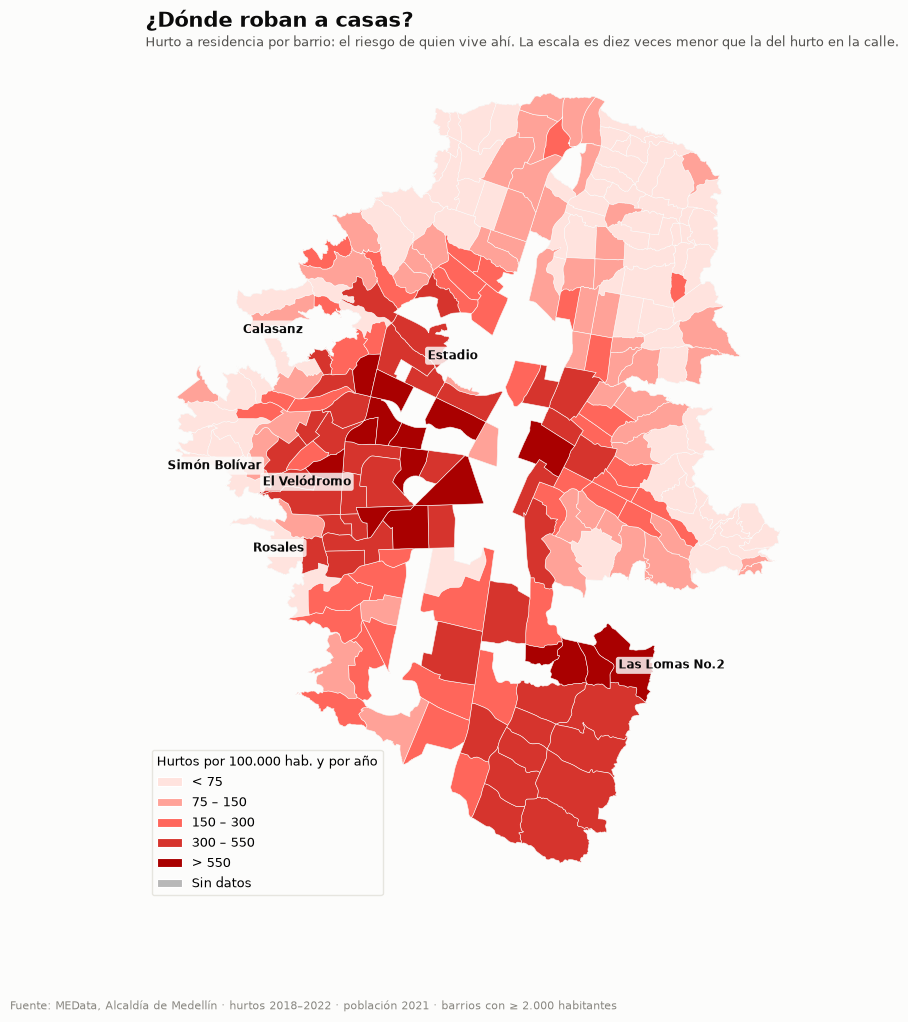

In [8]:
# 1. Ajustes de ubicación para los nombres de barrios en el mapa de residencias
ANOTAR_RESIDENCIA = [ ("1407", (1400, 0)), ("1211", (-2200, 0)), ("1113", (1200, 700)), ("1112", (-1600, -1200)), ("1202", (-1800, 900)), ("1602", (-2600, -400)) ]

# 2. Renderizado limpio usando la Vista 1 (Hurto a Residencia) de mapa_hurto.py
mapa_hurto.dibujar(barrios, mapa_hurto.VISTAS[1], anotar=ANOTAR_RESIDENCIA)

---

### 4.3. Autocorrelación Espacial: ¿Se agrupa el delito?

Mediante el indicador de autocorrelación espacial (**I de Moran**), evaluamos si los barrios con altas tasas delictivas se agrupan geográficamente:

$$I = \frac{\sum_i \sum_j w_{ij}\, z_i\, z_j}{\sum_i z_i^2}$$

donde $w_{ij}$ es 1 (normalizado) si los barrios $i$ y $j$ son vecinos y 0 si no.

| I de Moran | Lectura |
|---|---|
| $I > 0$ | Barrios similares |
| $I \approx 0$ | Mapa aleatorio |
| $p$ | Permutaciones |




> **Pregunta de discusión:** ¿Por qué un delito oportunista en la vía pública tendería a dispersarse en el mapa ($I\text{ de Moran}$ bajo), mientras que el hurto a vivienda tiende a formar "manchones" o conglomerados de barrios vecinos ($I\text{ de Moran}$ alto)?

In [9]:
# Matriz de Pesos Queen: Dos barrios son vecinos si sus polígonos se tocan, aunque sea en un punto
w = Queen.from_dataframe(barrios, use_index=True)
w.transform = "r"

# Moran Global: Calcula $I$ y su valor $p$ para evaluar si el patrón general es aleatorio o agrupado.
for col in ["tasa", "tasa_calle", "tasa_residencia"]:
    m = Moran(barrios[col], w)
    print(f"  {col:<18} I = {m.I:6.3f}   p = {m.p_sim:.3f}")

# Identifica geográficamente cuáles barrios forman clústeres estadísticamente significativos ($p < 0.05$).
local = Moran_Local(barrios["tasa"], w, seed=0)

# Tabla de Cuadrantes
barrios["cuadrante"] = pd.Series(local.q, index=barrios.index).map(
    {1: "Alto-Alto", 2: "Bajo-Alto", 3: "Bajo-Bajo", 4: "Alto-Bajo"})
barrios.loc[local.p_sim >= 0.05, "cuadrante"] = "No significativo"

print()
print(barrios.groupby("cuadrante").agg(
    barrios=("nombre", "count"), poblacion=("poblacion", "sum"),
    hurtos=("total", "sum")).to_string())

  tasa               I =  0.203   p = 0.001
  tasa_calle         I =  0.189   p = 0.001
  tasa_residencia    I =  0.693   p = 0.001

                  barrios  poblacion    hurtos
cuadrante                                     
Alto-Alto              14    98512.0   47205.0
Bajo-Alto               1     8475.0     677.0
Bajo-Bajo              56   638863.0   13310.0
No significativo      159  1475762.0  124334.0


## Hallazgos I de Moran:

| Variable | I de Moran | Hallazgo |
|---|---|---|
| Hurto total | 0,20 | Agrupación débil |
| Hurto en la calle | 0,19 | Agrupación débil |
| **Hurto a residencia** | **0,69** | Agrupación fuerte |

La diferencia es el hallazgo:

- Los **14 barrios Alto-Alto** (hurto alto rodeado de hurto alto) son el centro y
Laureles. Concentran **47.205 hurtos con 98.512 habitantes** — una cuarta parte del
total de la ciudad en el 4% de la población.

- Los **56 Bajo-Bajo** son la periferia: 638.863 personas y solo 13.310 hurtos.

- **Hurto en Vía Pública ($I = 0,19$):**
Muestra una agrupación espacial muy débil. Es un delito móvil y de oportunidad que sigue el movimiento de peatones y los picos de salida laboral (**17:00 a 20:00 horas**).

- **Hurto a Residencia ($I = 0,69$):**
Presenta una fuerte autocorrelación espacial, estructurando un corredor continuo en el occidente de la ciudad (El Poblado, Laureles, La América y Belén).

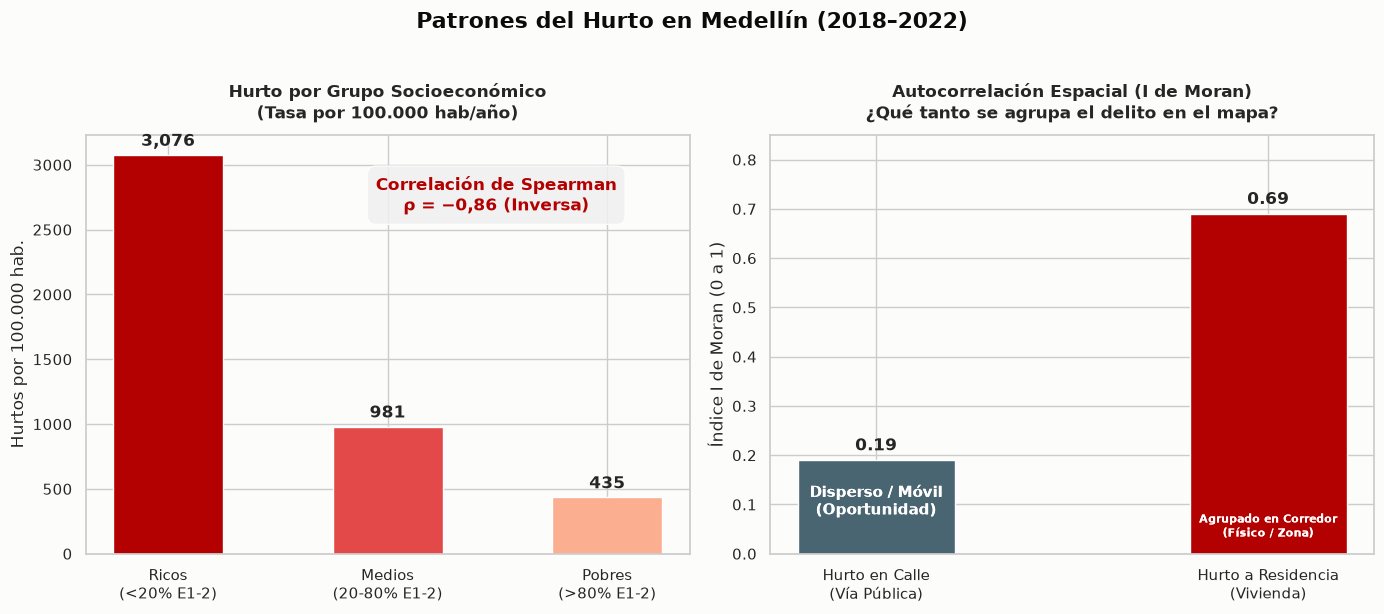

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética
sns.set_theme(style='whitegrid', font='DejaVu Sans')
FONDO = '#fcfcfb'
ROJO_OSCURO = '#b30000'
ROJO_MEDIO = '#e34948'
ROJO_CLARO = '#fcae91'
AZUL_GRIS = '#4a6572'
TINTA = '#0b0b0b'

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), facecolor=FONDO)
fig.suptitle('Patrones del Hurto en Medellín (2018–2022)', fontsize=16, fontweight='bold', color=TINTA, y=1.02)

# Panel 1: Tasas por Estrato

grupos = ['Ricos\n(<20% E1-2)', 'Medios\n(20-80% E1-2)', 'Pobres\n(>80% E1-2)']
tasas = [3076, 981, 435]
tasas = ax1.bar(grupos, tasas, color=[ROJO_OSCURO, ROJO_MEDIO, ROJO_CLARO], width=0.5)
ax1.set_title('Hurto por Grupo Socioeconómico\n(Tasa por 100.000 hab/año)', fontsize=12, fontweight='bold', pad=12)
ax1.set_ylabel('Hurtos por 100.000 hab.')
ax1.set_facecolor(FONDO)

for bar in ax1.patches:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 70, f'{int(yval):,}',
ha='center', fontweight='bold')
    
ax1.text(0.68, 0.82, 'Correlación de Spearman\nρ = −0,86 (Inversa)', transform=ax1.transAxes, ha='center',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='#f0f0f0', alpha=0.85), fontweight='bold', color=ROJO_OSCURO)

# Panel 2: I de Moran por Modalidad

modalidades = ['Hurto en Calle\n(Vía Pública)', 'Hurto a Residencia\n(Vivienda)']
moran_vals = [0.19, 0.69]
ax2.bar(modalidades, moran_vals, color=[AZUL_GRIS, ROJO_OSCURO], width=0.4)
ax2.set_title('Autocorrelación Espacial (I de Moran)\n¿Qué tanto se agrupa el delito en el mapa?', fontsize=12, fontweight='bold', pad=12)
ax2.set_ylabel('Índice I de Moran (0 a 1)')
ax2.set_ylim(0, 0.85)
ax2.set_facecolor(FONDO)

for bar in ax2.patches:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.2f}', ha='center', fontweight='bold')
    ax2.text(0, 0.08, 'Disperso / Móvil\n(Oportunidad)', ha='center', fontweight='bold', color='white', fontsize=10.5)
    ax2.text(1, 0.035, 'Agrupado en Corredor\n(Físico / Zona)', ha='center', fontweight='bold', color='white', fontsize=8.2)
    
plt.tight_layout()
plt.savefig('grafica_comparativa_hurto.png', dpi=200, bbox_inches='tight')
plt.show()

---

### 4.4. Para la propuesta de política pública: lugar, modalidad y hora

Un mapa dice **dónde**. Para saber **qué hacer** hay que analizar a profundidad los datos registrados respecto al hurto a persona, que es el 77% del total de estos.

**Dónde ocurre** (2018–2022):

| Lugar | Casos |
|---|---|
| Vía pública | 83.479 |
| Estación del Metro | 10.134 |
| Almacén o tienda | 9.601 |
| Residencia | 6.386 |
| Bus de servicio público | 5.407 |
| Centro comercial | 5.064 |

**Cómo ocurre:**

| Modalidad | Casos |
|---|---|
| Atraco | 94.529 |
| Descuido | 34.105 |
| Cosquilleo | 27.187 |
| Raponazo | 10.865 |

**Con qué:** Sin arma 92.106; arma de fuego 48.848; arma cortopunzante 32.282.

**A qué hora:** El pico va de **17h a 20h** (10.737 casos a las 18h), justo la
salida laboral. El mínimo es 23h–03h.

> **Pregunta de discusión:** Si el $I\text{ de Moran}$ revela que el hurto a personas no forma conglomerados fijos pero el hurto a vivienda sí, ¿tendría sentido aplicar la misma estrategia de cuadrantes fijos de policía para ambos delitos?

In [11]:
persona = pd.read_csv(ARCHIVOS["persona"], dtype=str, low_memory=False,
                      usecols=["fecha_hecho", "lugar", "modalidad", "arma_medio"])
persona["fecha"] = pd.to_datetime(persona["fecha_hecho"], errors="coerce")
persona = persona[persona["fecha"].dt.year.between(ANIO_INI, ANIO_FIN)]

print(f"Hurto a persona 2018-2022: {len(persona):,}\n")
for columna, titulo in [("lugar", "LUGAR"), ("modalidad", "MODALIDAD"),
                        ("arma_medio", "ARMA")]:
    print(f"=== {titulo} ===")
    print(persona[columna].value_counts().head(6).to_string())
    print()

Hurto a persona 2018-2022: 184,582

=== LUGAR ===
lugar
Vía pública                83479
Estación del Metro         10134
Almacén tienda y otro       9601
Residencia                  6386
Bus de servicio público     5407
Centro comercial            5064

=== MODALIDAD ===
modalidad
Atraco                   94529
Descuido                 34105
Cosquilleo               27187
Raponazo                 10865
Rompimiento cerraduta     3919
Engaño                    3061

=== ARMA ===
arma_medio
No                    92106
Arma de fuego         48848
Arma cortopunzante    32282
Objeto contundente     6585
Escopolamina           3944
Sin dato                779



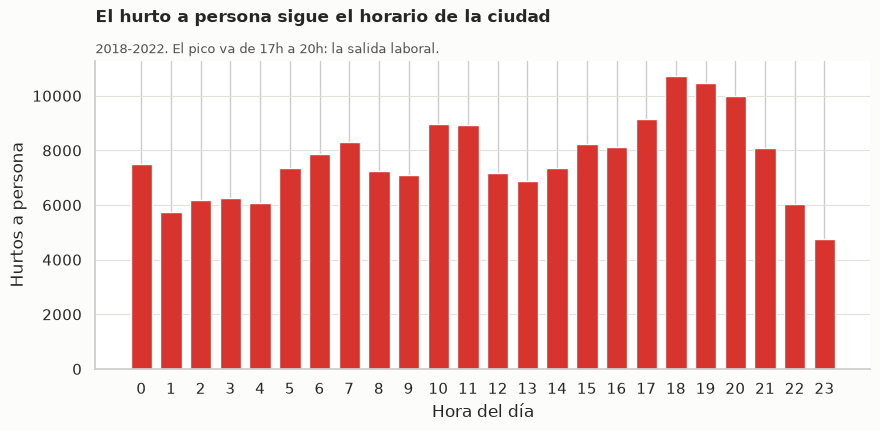

In [12]:
# Paleta de colores y constantes de diseño
TINTA = "#0b0b0b"
TINTA_2 = "#52514e"
TINTA_SUAVE = "#898781"
FONDO = "#fcfcfb"

# Conteo de hurtos a persona por hora del día
horas = persona["fecha"].dt.hour.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4), facecolor=FONDO)
ax.bar(horas.index, horas.values, color=ROJA[3], width=0.72)
ax.set_xticks(range(0, 24))
ax.set_xlabel("Hora del día")
ax.set_ylabel("Hurtos a persona")
ax.set_title("El hurto a persona sigue el horario de la ciudad",
             loc="left", fontweight="bold", pad=28)
ax.text(0, 1.015, "2018-2022. El pico va de 17h a 20h: la salida laboral.",
        transform=ax.transAxes, fontsize=9.5, color=TINTA_2, va="bottom")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
plt.show()

---

## V. Recomendaciones de política pública

Gracias a estos datos encontramos cuatro hallazgos relevantes para analizar y proponer una política pública apropiada según el caso en concreto:

### A. El hurto es de oportunidad y sigue el horario laboral

Atraco (51,2%) y descuido (18,5%) dominan; el pico es 17h–20h; el 45,2% ocurre en vía pública. **No es un delito de noche en callejones: es un delito de hora pico en corredores concurridos.**

- **Patrullaje por corredores, no por cuadrante.**
- Reforzar 16h–21h en los ejes comerciales y de transporte, no repartir la fuerza por área.
- **Cámaras y alumbrado en los nodos de transporte.** Estación del Metro es el segundo lugar (10.134 casos): es un punto fijo, concentrado y predecible.

### B. El centro y Laureles son el problema, no la periferia

La Candelaria tiene **11.398** hurtos por 100.000 hab/año; Popular y Santa Cruz,
**369**. Una diferencia de **31 veces**.

- **El presupuesto de seguridad debe seguir al delito, no a la pobreza.** Hoy el reflejo es mandar más policía a la periferia. Los datos dicen lo contrario.
- **Pero cuidado con la lectura fácil.** Los barrios ricos tienen más hurto *reportado*: Hay más que robar, más denuncia y más seguros. Parte de la brecha es de reporte, no de delito. Antes de mover recursos, hay que medir la subdenuncia en la periferia.

### C. El hurto a la casa es un problema de zona

Con I de Moran de **0,69**, el hurto a residencia se agrupa. Los diez barrios con más hurto a la casa forman un corredor continuo del occidente: Las Lomas No. 1 y No. 2 (El Poblado), Simón Bolívar y Calasanz (La América), Estadio, El Velódromo, Florida Nueva y Bolivariana (Laureles), Rosales (Belén) y La Candelaria.

- **Intervención por zona, no por barrio.** La sesión 6 ya enseñó que las islas de
  carencia cruzan límites de comuna. Aquí pasa lo mismo: la zona de hurto
  residencial cruza El Poblado, Laureles, La América y Belén.
- **Prevención situacional:** portería, alumbrado, diseño de accesos, alarmas
  comunitarias. Es un delito de acceso, no de calle.

### D. El hurto no se reparte como la carencia

Este es el punto de política más importante, y el que conecta con la sesión 6:

| Problema | Dónde se concentra | Instrumento |
|---|---|---|
| **Carencia urbana** | periferia pobre (Manrique, Popular) | vivienda, servicios, espacio público |
| **Hurto** | centro y sur ricos (Candelaria, Laureles) | prevención situacional, patrullaje |

**Son dos políticas distintas y no compiten por el mismo peso.** Repartir el
Presupuesto Participativo con un índice de carencia y el de seguridad con un mapa
de delito es correcto. Lo incorrecto sería usar uno para justificar el otro.

### Lo que estos datos no pueden decir

- **Subdenuncia.** Una tasa baja puede ser un barrio seguro o un barrio donde no se
  denuncia. Los datos son de denuncia, no de delito.
- **Población flotante.** El Poblado, Guayaquil y La Candelaria reciben mucha más
  gente de la que registran. Su tasa está inflada.
- **El móvil del delito.** No se puede separar el hurto del habitante del hurto del
  visitante.
- **2023 quedó fuera** (llega a noviembre) y `hurto a establecimiento` se corta en
  2017.

---

## VI. Resumen de la sesión

| Tema | Herramientas clave |
|---|---|
| Datos | 6 conjuntos de MEData, `pd.to_datetime()`, filtrar por año |
| Agregar | `groupby()`, `lstrip("#")` en el código de barrio, join contra el geojson |
| Tasas | División por población y por años; el sesgo del denominador |
| Color | Rampa secuencial de un tono en OKLCH, luminosidad monótona, gris para "sin datos" |
| Comparar mapas | Una escala por vista; el mismo dato con otra escala cuenta otra historia |
| Agrupación | `Queen.from_dataframe()`, `Moran()`, `Moran_Local()` |
| Política | Más allá del lugar × modalidad × hora para pasar del dónde al qué |

**Respuestas del caso:**

- El hurto en Medellín **no** se concentra en la periferia pobre, sino en el centro y el sur ricos (ρ = −0,86 con el estrato).
La Candelaria tiene 31 veces la tasa de Popular.
- El hurto en la calle es de oportunidad y sigue el horario laboral (pico 17h–20h, 45% en vía pública).
- El hurto a la casa sí se agrupa en el mapa (I = 0,69) y pide intervención por zona.
- Esta diferencia exige separar la inversión social en la periferia de las estrategias operativas de seguridad en los nodos de alta circulación.

---

## VIII. Cierre: Preguntas de discusión

1. Vuelvan a la pregunta 1 del inicio. Después de ver los datos, ¿sigue en pie su respuesta? ¿Qué la cambiaría?
2. Si fueran secretarios de seguridad, ¿cómo explicarían a una junta comunal de un barrio periférico como Manrique, por ejemplo, que el refuerzo policial se dirigirá a un nodo de transporte comercial?
3. La subdenuncia puede explicar parte de la brecha. ¿Cómo la medirían con los datos que tienen? ¿Qué fuente pedirían?

---

## VII. Exportación de datos

Guardamos la tabla por barrio en `datalake/data/processed/hurto/`.
De igual manera, se guarda **un CSV**: Pues un mapa nunca debe ser la única forma de leer un dato.

In [13]:
# Guardado en datalake
export.guardar_resultados(barrios, TIPOS, SALIDA)

✅ Exportados 230 barrios a c:\Users\USER\Documents\Marie's\Uni\UdeA\Python\Hurto_Medellin_Proyecto\datalake\data\processed\hurto
